In [1]:
import ast
import os
from collections import Counter
from dotenv import load_dotenv

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

load_dotenv()
os.chdir(os.getenv("ROOT"))

from notebooks.utils import (
    construct_hierarchy,
    flatten_dict_keys,
    translate_source_categories,
)

In [2]:
TEST_SIZE = float(os.getenv("TEST_SIZE"))
RANDOM_STATE = int(os.getenv("RANDOM_STATE"))
TWEETS_CSV = os.getenv("TWEETS_CSV")

In [3]:
tweets_with_relevance = pd.read_csv(filepath_or_buffer=TWEETS_CSV)
tweets_with_relevance.dropna(subset=["relevant"])

print(f"There are {tweets_with_relevance.shape[0]} tweets")
tweets_with_relevance.head()

There are 21368 tweets


,_id,date,id,relevant,text,tweet,type,watson,annotation,urls,destination_url,valid_certificate
0,b'5b88752abb325e65390af240',2018-08-30 22:52:25+00:00,1035299228984041472,False,Best way to build empathy is through honesty a...,{'created_at': 'Thu Aug 30 22:52:25 +0000 2018...,vulnerability,"{'usage': {'text_units': 1, 'text_characters':...",irrelevant,[],NaN,NaN
1,b'5b8875d5bb325e65a22cf81b',2018-08-30 22:55:15+00:00,1035299941932036096,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:55:15 +0000 2018...,ransomware,"{'usage': {'text_units': 1, 'text_characters':...",business,['https://ubm.io/2MCQwfg'],https://www.darkreading.com/endpoint-security,False
2,b'5b88768dbb325e65fa7e78e3',2018-08-30 22:58:20+00:00,1035300715470757889,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:58:20 +0000 2018...,ransomware,"{'usage': {'text_units': 1, 'text_characters':...",business,['http://quantus.biz/security/2018/08/30/crypt...,http://www.quantusintel.group/,True
3,b'5b8876f9bb325e65fa7e78e4',2018-08-30 23:00:08+00:00,1035301167952211969,True,Protect your customers access Prestashop Ant...,{'created_at': 'Thu Aug 30 23:00:08 +0000 2018...,ddos,"{'usage': {'text_units': 1, 'text_characters':...",threat,['http://addons.prestashop.com/en/23513-anti-d...,https://addons.prestashop.com/en/23513-anti-dd...,True
4,b'5b8876f9bb325e65fa7e78e5',2018-08-30 23:00:09+00:00,1035301173178249217,True,Data leak from Huazhu Hotels may affect 130 mi...,{'created_at': 'Thu Aug 30 23:00:09 +0000 2018...,leak,"{'usage': {'text_units': 1, 'text_characters':...",threat,['http://www.hotelmanagement.net/tech/data-lea...,http://www.hotelmanagement.net/tech/data-leak-...,True


In [4]:
X_train_val, X_test = train_test_split(
    tweets_with_relevance,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=tweets_with_relevance["relevant"],
)

X_train_val.shape, X_test.shape

((17094, 12), (4274, 12))

In [5]:
with open(os.getenv("FILTER_TRAIN_CSV"), "wb") as f:
    X_train_val.to_csv(path_or_buf=f)

with open(os.getenv("FILTER_TEST_CSV"), "wb") as f:
    X_test.to_csv(path_or_buf=f)

In [6]:
X_train_val = pd.read_csv(filepath_or_buffer=os.getenv("FILTER_TRAIN_CSV"))
X_test = pd.read_csv(filepath_or_buffer=os.getenv("FILTER_TEST_CSV"))

X_train_val.shape, X_test.shape

((17094, 13), (4274, 13))

In [7]:
CATEGORIES_MAPPING = {
    "computer security": "computer security",
    "operating systems": "operating systems",
    "software": "software",
    "programming languages": "software",
    "hardware": "hardware",
    "electronic components": "hardware",
    "networking": "networking",
    "internet technology": "networking",
    "network security": "network security",
    "antivirus and malware": "antivirus and malware",
    "mac os": "mac os",
    "windows": "windows",
    "unix": "unix",
    "linux": "linux",
    "databases": "databases",
    "computer": "computer",
    "computer components": "computer components",
    "computer networking": "computer networking",
    "servers": "servers",
    "portable computer": "portable computer",
    "desktop computer": "desktop computer",
    "router": "router",
    "wireless technology": "wireless technology",
}

categorized_tweets_df = (
    pd.read_csv(filepath_or_buffer=TWEETS_CSV).assign(
        tweet=lambda df: df["tweet"].apply(func=ast.literal_eval),
        watson=lambda df: df["watson"]
        .apply(func=ast.literal_eval)
        .apply(func=lambda x: x.get("categories", []))
        .apply(func=construct_hierarchy),
        watson_list=lambda df: df["watson"].apply(func=flatten_dict_keys),
        target=lambda df: df["watson_list"].apply(
            func=translate_source_categories, args=(CATEGORIES_MAPPING,)
        ),
    )
    # .query(expr='relevant == True')
)
# exclude_other_categories = ['other' in target_i for target_i in categories_df['target']]
# categories_df_temp = categories_df[exclude_other_categories]
# categories_df_temp = categories_df_temp[categories_df_temp['relevant'] == False]
# categories_df = categories_df.loc[list(set(categories_df.index) - set(categories_df_temp.index))]
# categories_df = categories_df.reset_index(drop=True)

print(f"There are {categorized_tweets_df.shape[0]} tweets")
categorized_tweets_df.head()

There are 21368 tweets


,_id,date,id,relevant,text,tweet,type,watson,annotation,urls,destination_url,valid_certificate,watson_list,target
0,b'5b88752abb325e65390af240',2018-08-30 22:52:25+00:00,1035299228984041472,False,Best way to build empathy is through honesty a...,{'created_at': 'Thu Aug 30 22:52:25 +0000 2018...,vulnerability,{'science': {'social science': {'philosophy': ...,irrelevant,[],NaN,NaN,"[science, social science, philosophy, ethics, ...","[network security, computer security]"
1,b'5b8875d5bb325e65a22cf81b',2018-08-30 22:55:15+00:00,1035299941932036096,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:55:15 +0000 2018...,ransomware,{'technology and computing': {'computer securi...,business,['https://ubm.io/2MCQwfg'],https://www.darkreading.com/endpoint-security,False,"[technology and computing, computer security, ...","[antivirus and malware, computer, hardware, co..."
2,b'5b88768dbb325e65fa7e78e3',2018-08-30 22:58:20+00:00,1035300715470757889,False,Cryptocurrency Scams Replacing Ransomware as A...,{'created_at': 'Thu Aug 30 22:58:20 +0000 2018...,ransomware,{'technology and computing': {'computer securi...,business,['http://quantus.biz/security/2018/08/30/crypt...,http://www.quantusintel.group/,True,"[technology and computing, computer security, ...","[antivirus and malware, computer, hardware, co..."
3,b'5b8876f9bb325e65fa7e78e4',2018-08-30 23:00:08+00:00,1035301167952211969,True,Protect your customers access Prestashop Ant...,{'created_at': 'Thu Aug 30 23:00:08 +0000 2018...,ddos,{'technology and computing': {'internet techno...,threat,['http://addons.prestashop.com/en/23513-anti-d...,https://addons.prestashop.com/en/23513-anti-dd...,True,"[technology and computing, internet technology...","[antivirus and malware, networking, software, ..."
4,b'5b8876f9bb325e65fa7e78e5',2018-08-30 23:00:09+00:00,1035301173178249217,True,Data leak from Huazhu Hotels may affect 130 mi...,{'created_at': 'Thu Aug 30 23:00:09 +0000 2018...,leak,"{'travel': {'hotels': {}}, 'home and garden': ...",threat,['http://www.hotelmanagement.net/tech/data-lea...,http://www.hotelmanagement.net/tech/data-leak-...,True,"[travel, hotels, home and garden, home improve...",[other]


Target Frequencies:
computer security: 9216
other: 8013
antivirus and malware: 5854
software: 5214
network security: 4321
hardware: 2998
computer: 2210
databases: 1885
networking: 1340
operating systems: 1271
linux: 541
computer networking: 359
windows: 350
computer components: 341
router: 337
unix: 178
mac os: 154
portable computer: 112
servers: 84
wireless technology: 25
desktop computer: 10


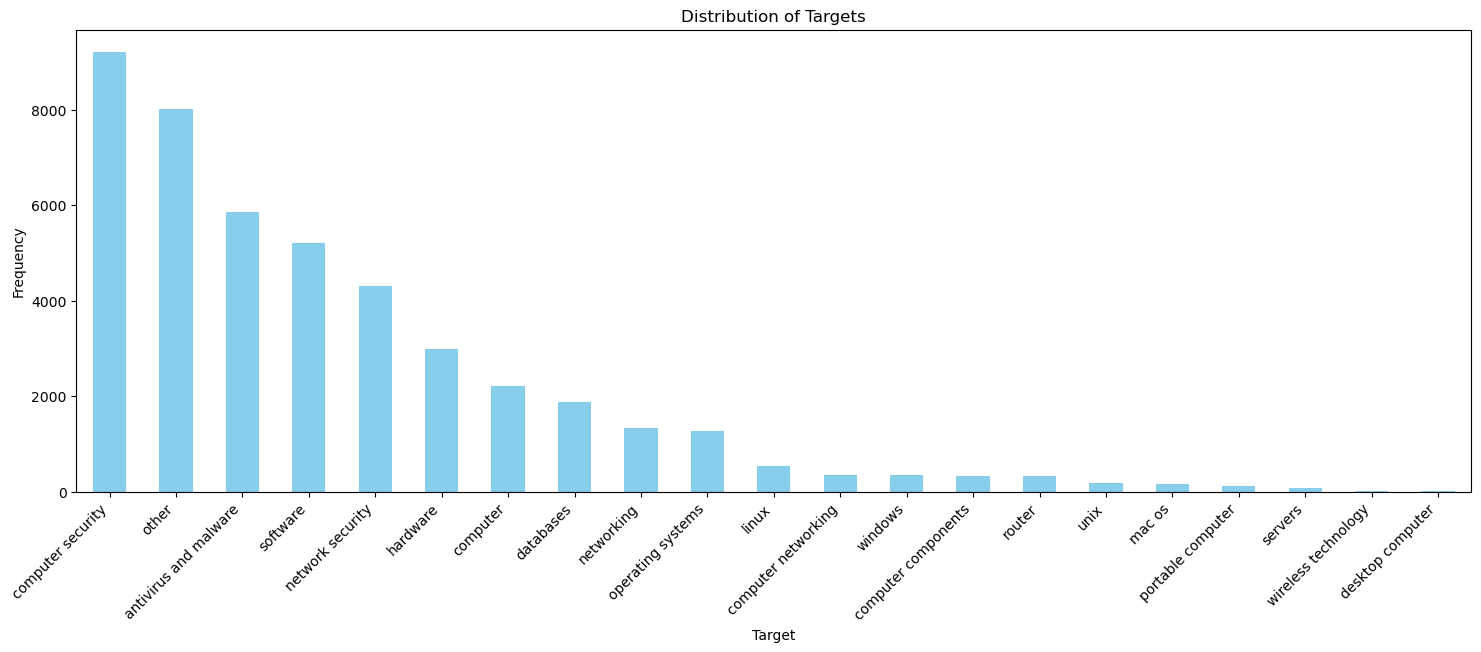

In [8]:
target_frequency_count = Counter(
    [item for sublist in categorized_tweets_df["target"] for item in sublist]
)

print("Target Frequencies:")
for target, freq in target_frequency_count.most_common():
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
pd.Series(data=target_frequency_count).sort_values(ascending=False).plot(
    kind="bar", color="skyblue"
)
plt.title("Distribution of Targets")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

Most Common Targets:
('other',): 8013
('antivirus and malware', 'computer security'): 2316
('network security', 'computer security'): 2082
('software',): 715
('antivirus and malware', 'network security', 'computer security'): 704
('antivirus and malware', 'software', 'computer security'): 554
('antivirus and malware', 'computer', 'hardware', 'computer security'): 465
('databases', 'software'): 457
('computer', 'hardware'): 448
('antivirus and malware', 'databases', 'software', 'computer security'): 414
('networking',): 382
('network security', 'software', 'computer security'): 369
('databases', 'network security', 'software', 'computer security'): 307
('antivirus and malware', 'computer', 'software', 'computer security', 'hardware'): 256
('hardware', 'software', 'computer'): 171
('antivirus and malware', 'networking', 'software', 'computer security'): 155
('hardware', 'computer components'): 148
('antivirus and malware', 'networking', 'computer security'): 128
('networking', 'software'

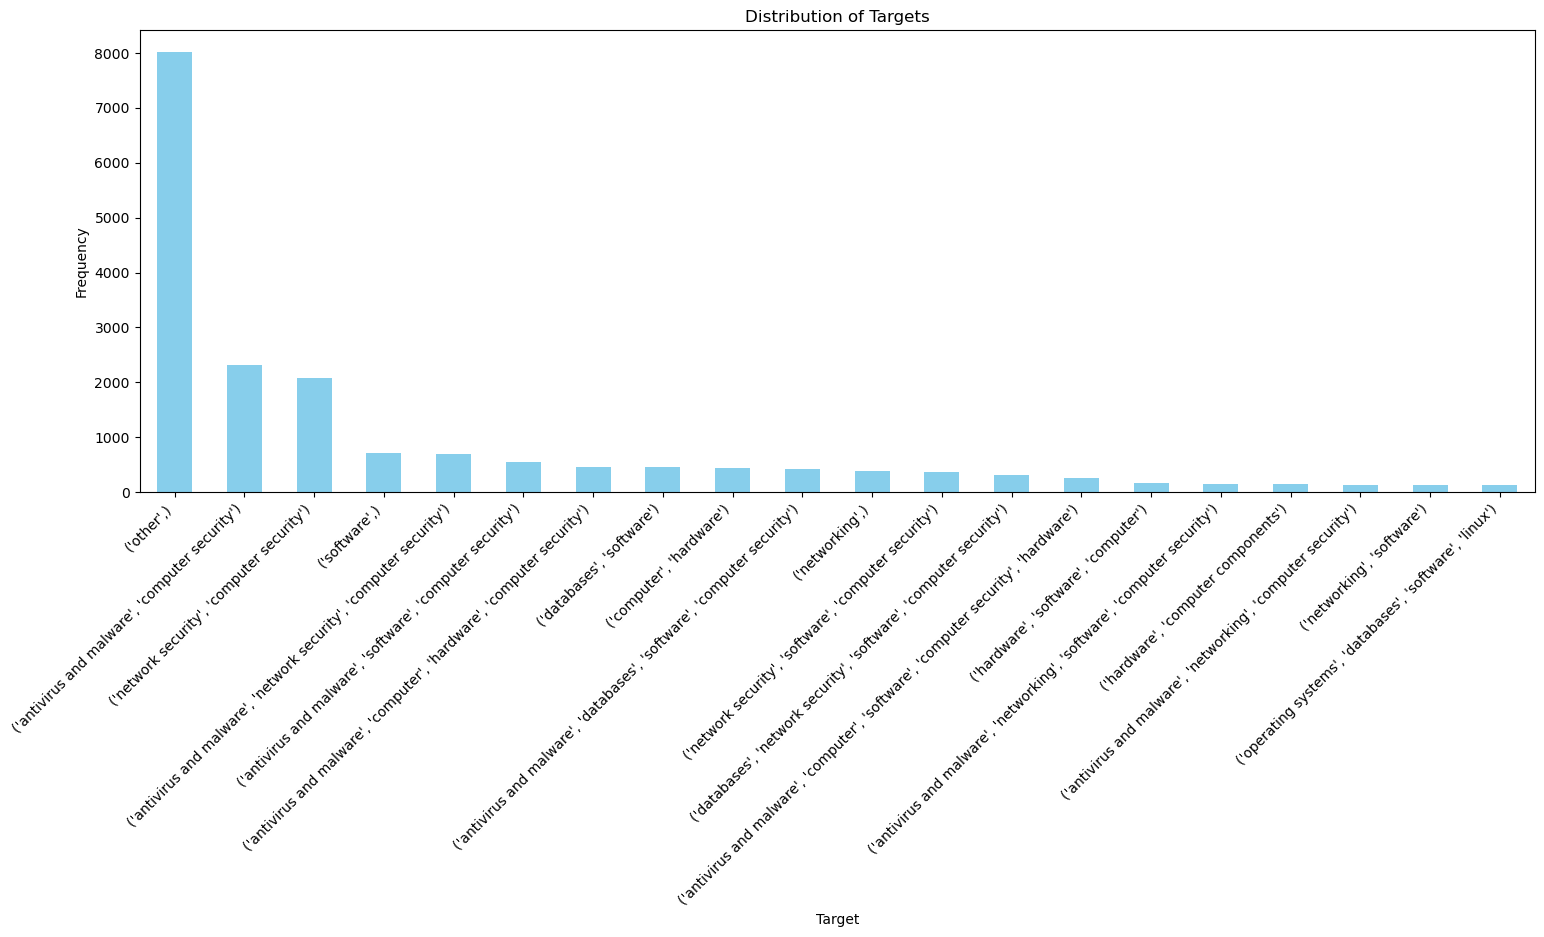

Least Common Targets:
('operating systems', 'router', 'linux', 'computer networking', 'hardware'): 1
('operating systems', 'antivirus and malware', 'software', 'databases', 'linux', 'computer security'): 1
('operating systems', 'networking', 'software'): 1
('hardware', 'servers', 'computer'): 1
('operating systems', 'unix', 'antivirus and malware', 'linux', 'computer security'): 1
('operating systems', 'antivirus and malware', 'windows', 'software', 'databases', 'computer security'): 1
('operating systems', 'databases', 'software', 'mac os'): 1
('operating systems', 'unix', 'software', 'databases', 'linux'): 1
('operating systems', 'unix', 'antivirus and malware', 'computer security'): 1
('operating systems', 'windows', 'networking'): 1
('computer networking', 'hardware', 'router'): 1
('antivirus and malware', 'networking', 'hardware', 'computer security'): 1
('operating systems', 'portable computer', 'computer', 'hardware', 'mac os'): 1
('operating systems', 'networking'): 1
('compute

In [9]:
target_frequency_count = Counter(
    tuple(item) for item in categorized_tweets_df["target"]
)
cut = min(len(target_frequency_count), 20)

print("Most Common Targets:")
for target, freq in target_frequency_count.most_common()[:cut]:
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
(
    pd.Series(data={str(k): v for k, v in target_frequency_count.most_common()[:cut]})
    .sort_values(ascending=False)
    .plot(kind="bar", color="skyblue")
)
plt.title("Distribution of Targets")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

print("Least Common Targets:")
for target, freq in target_frequency_count.most_common()[-cut:]:
    print(f"{target}: {freq}")

In [10]:
mlb = MultiLabelBinarizer()
y = mlb.fit_transform(y=categorized_tweets_df["target"])
labels_map, _ = np.unique(ar=y, axis=0, return_inverse=True)

Updated Target Frequencies:
('other',): 8013
('antivirus and malware', 'computer security'): 2316
('network security', 'computer security'): 2082
('software',): 715
('antivirus and malware', 'network security', 'computer security'): 704
('antivirus and malware', 'software', 'computer security'): 554
('antivirus and malware', 'computer', 'hardware', 'computer security'): 465
('databases', 'software'): 457
('computer', 'hardware'): 448
('antivirus and malware', 'databases', 'software', 'computer security'): 414
('networking',): 382
('network security', 'software', 'computer security'): 369
('databases', 'network security', 'software', 'computer security'): 307
('antivirus and malware', 'computer', 'software', 'computer security', 'hardware'): 256
('hardware', 'software', 'computer'): 171
('antivirus and malware', 'networking', 'software', 'computer security'): 155
('hardware', 'computer components'): 148
('antivirus and malware', 'networking', 'computer security'): 128
('networking', 'so

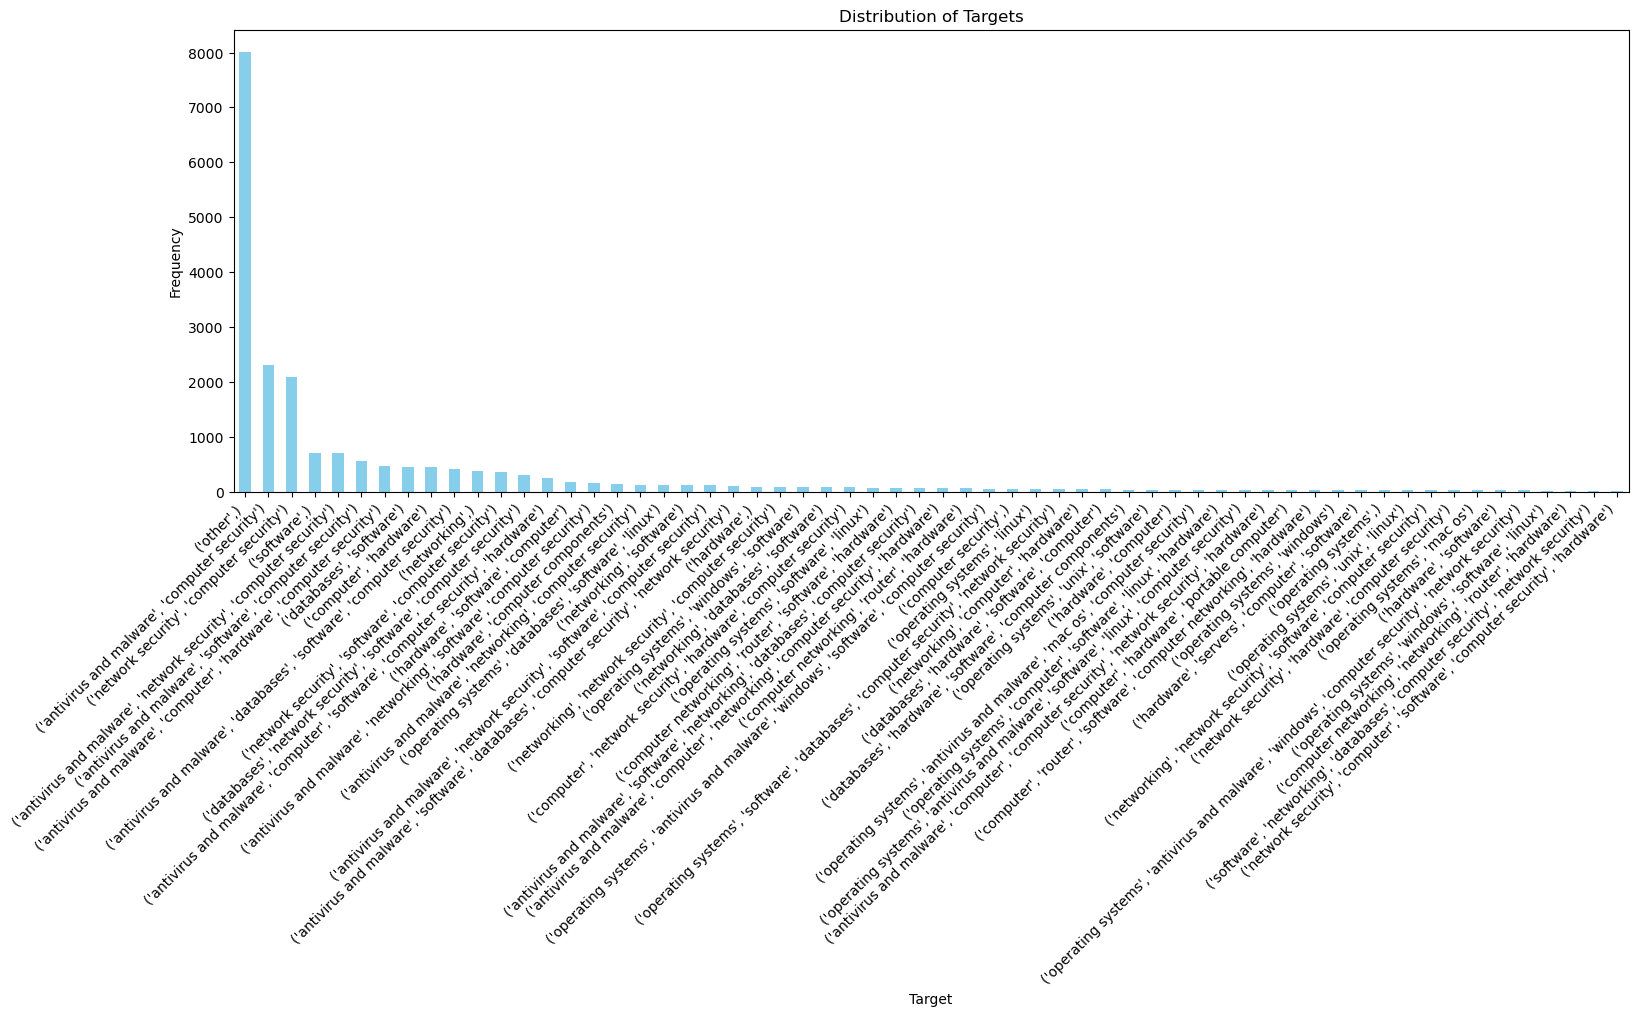

In [11]:
valid_targets = {target for target, freq in target_frequency_count.items() if freq >= 20}

# Filter the DataFrame to keep only valid targets
categorized_tweets_df = categorized_tweets_df[
    categorized_tweets_df["target"].apply(lambda x: tuple(x) in valid_targets)
]
categorized_tweets_df = categorized_tweets_df.reset_index(drop=True)

# Print the updated target frequencies
updated_target_freq = Counter(tuple(item) for item in categorized_tweets_df["target"])
print("Updated Target Frequencies:")
for target, freq in updated_target_freq.most_common():
    print(f"{target}: {freq}")

_, ax = plt.subplots(figsize=(18, 6))
(
    pd.Series(data={str(k): v for k, v in updated_target_freq.items()})
    .sort_values(ascending=False)
    .plot(kind="bar", color="skyblue")
)
plt.title("Distribution of Targets")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

In [12]:
_, y_mcp = np.unique(
    ar=mlb.transform(categorized_tweets_df["target"]), axis=0, return_inverse=True
)

X_train_val, X_test = train_test_split(
    categorized_tweets_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=y_mcp,
)

In [13]:
with open(f"{os.getenv("TEMP_CATEGORIES_TRAIN_CSV")}", "wb") as f:
    X_train_val.to_csv(path_or_buf=f)

with open(f"{os.getenv("TEMP_CATEGORIES_TEST_CSV")}", "wb") as f:
    X_test.to_csv(path_or_buf=f)